# Bayesian Network Analysis

This analysis uses a Bayesian Network to examine the relationships between
selected customer variables and credit card default. This analysis uses a Bayesian Network to examine the relationships between selected customer variables and credit card default. The model will identify probabilistic relationships between customer characteristics, previous payment behavior, and DEFAULT.

In [1]:
## 2. Imports/Libraries

#Install pgmpy for Bayesian Network analysis.
!pip install pgmpy -q

#Import libraries needed for Bayesian Network analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import warnings

from pgmpy.estimators import HillClimbSearch
from pgmpy.estimators import BIC
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

#Hide HillClimbSearch deprecation warning
warnings.filterwarnings(
    "ignore",
    message="HillClimbSearch is deprecated.*",
    category=FutureWarning
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.6 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [2]:
## 3. Upload Dataset

#Upload the cleaned credit card dataset.
from google.colab import files

uploaded = files.upload()

#Load the uploaded dataset.
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

#Display the first five observations.
df.head()

Saving cleaned_credit_card_data.csv to cleaned_credit_card_data.csv


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
## 4. Select Bayesian Network Variables

#Select variables for Bayesian Network
bayesian_variables = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "DEFAULT"
]

#Create Bayesian Network dataset
bayesian_df = df[bayesian_variables].copy()

#Display dataset information
print(f"Number of Observations: {bayesian_df.shape[0]:,}")
print(f"Number of Variables: {bayesian_df.shape[1]}")
print(f"Missing Values: {bayesian_df.isnull().sum().sum()}")

Number of Observations: 30,000
Number of Variables: 9
Missing Values: 0


Explanation:

For variable selection, the Bayesian model uses a subset of variables related to the customer’s credit limit, age, repayment status, and previous payment amounts. These variables were selected in order to keep the network manageable, but at the same time still include information that could help explain the relationships with credit card default.

The DEFAULT variable was used as the target variable for this analysis.

In [4]:
## 5. Discretize Continuous Variables

#Select continuous variables
continuous_variables = [
    "LIMIT_BAL",
    "AGE",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3"
]

#Create Low, Medium, and High categories
for variable in continuous_variables:
    bayesian_df[variable] = pd.qcut(
        bayesian_df[variable],
        q=3,
        labels=["Low", "Medium", "High"],
        duplicates="drop"
    )

#Display
bayesian_df.head()

,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_AMT1,PAY_AMT2,PAY_AMT3,DEFAULT
0,Low,Low,2,2,-1,Low,Low,Low,1
1,Medium,Low,-1,2,0,Low,Low,Low,1
2,Medium,Medium,0,0,0,Medium,Medium,Low,0
3,Low,Medium,0,0,0,Medium,Medium,Medium,0
4,Low,High,-1,0,-1,Medium,High,High,0


Explanation:

The continuous variables were divided into three separate categories: Low, Medium, and High, using three quantile groups. This allows the continuous numerical variables to be represented as discrete categories for the Bayesian Network. The repayment status and DEFAULT variables were already discrete and were converted to categorical variables before learning the network structure.

In [5]:
## 6. Check Discretized Variables

#Display the number of observations in each category
#for the discretized continuous variables.
for variable in continuous_variables:
    print(f"{variable}:")
    print(bayesian_df[variable].value_counts())
    print()

LIMIT_BAL:
LIMIT_BAL
Low       10799
High       9622
Medium     9579
Name: count, dtype: int64

AGE:
AGE
Low       11013
Medium     9843
High       9144
Name: count, dtype: int64

PAY_AMT1:
PAY_AMT1
Medium    10018
Low       10002
High       9980
Name: count, dtype: int64

PAY_AMT2:
PAY_AMT2
Low       10025
High       9999
Medium     9976
Name: count, dtype: int64

PAY_AMT3:
PAY_AMT3
Low       10794
High       9999
Medium     9207
Name: count, dtype: int64



In [6]:
## 7. Learn Bayesian Network Structure

#Select categorical variables
categorical_variables = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "DEFAULT"
]

#Convert variables to categorical
for variable in categorical_variables:
    bayesian_df[variable] = bayesian_df[variable].astype("category")

#Create Hill Climb Search
hill_climb = HillClimbSearch(bayesian_df)

#Learn Bayesian Network structure with BIC
best_model = hill_climb.estimate(
    scoring_method=BIC(bayesian_df),
    show_progress=False
)

#Display Network relationships
print("Bayesian Network Relationships:")

for edge in best_model.edges():
    print(f"{edge[0]} -> {edge[1]}")

Bayesian Network Relationships:
LIMIT_BAL -> PAY_AMT2
LIMIT_BAL -> PAY_2
LIMIT_BAL -> PAY_AMT1
LIMIT_BAL -> PAY_AMT3
LIMIT_BAL -> DEFAULT
AGE -> LIMIT_BAL
PAY_0 -> DEFAULT
PAY_2 -> PAY_0
PAY_2 -> PAY_3
PAY_2 -> PAY_AMT1
PAY_3 -> PAY_AMT2
PAY_AMT1 -> PAY_AMT3
PAY_AMT2 -> PAY_AMT1
PAY_AMT2 -> PAY_AMT3


Explanation:

This structure learning uses Hill Climb Search with the Bayesian Information Criterion (BIC) to determine the structure of the Bayesian Network. The model identified 14 relationships between the selected variables. What these relationships represent are the probabilistic dependencies found within the dataset and should in no way, shape, or form be interpreted as direct cause-and-effect relationships.

In [7]:
## 8. Create and Fit Bayesian Network

#Create the Bayesian Network using the relationships
#identified by Hill Climb Search.
bayesian_model = DiscreteBayesianNetwork(
    best_model.edges()
)

#Fit the Bayesian Network to the prepared dataset
#using Maximum Likelihood Estimation.
bayesian_model.fit(bayesian_df)

#Display the number of relationships in the network.
print(f"Number of Relationships: {len(bayesian_model.edges())}")

print("\nBayesian Network Relationships:")

for edge in bayesian_model.edges():
    print(f"{edge[0]} -> {edge[1]}")

Number of Relationships: 14

Bayesian Network Relationships:
LIMIT_BAL -> PAY_AMT2
LIMIT_BAL -> PAY_2
LIMIT_BAL -> PAY_AMT1
LIMIT_BAL -> PAY_AMT3
LIMIT_BAL -> DEFAULT
PAY_AMT2 -> PAY_AMT1
PAY_AMT2 -> PAY_AMT3
PAY_2 -> PAY_0
PAY_2 -> PAY_3
PAY_2 -> PAY_AMT1
PAY_AMT1 -> PAY_AMT3
AGE -> LIMIT_BAL
PAY_0 -> DEFAULT
PAY_3 -> PAY_AMT2


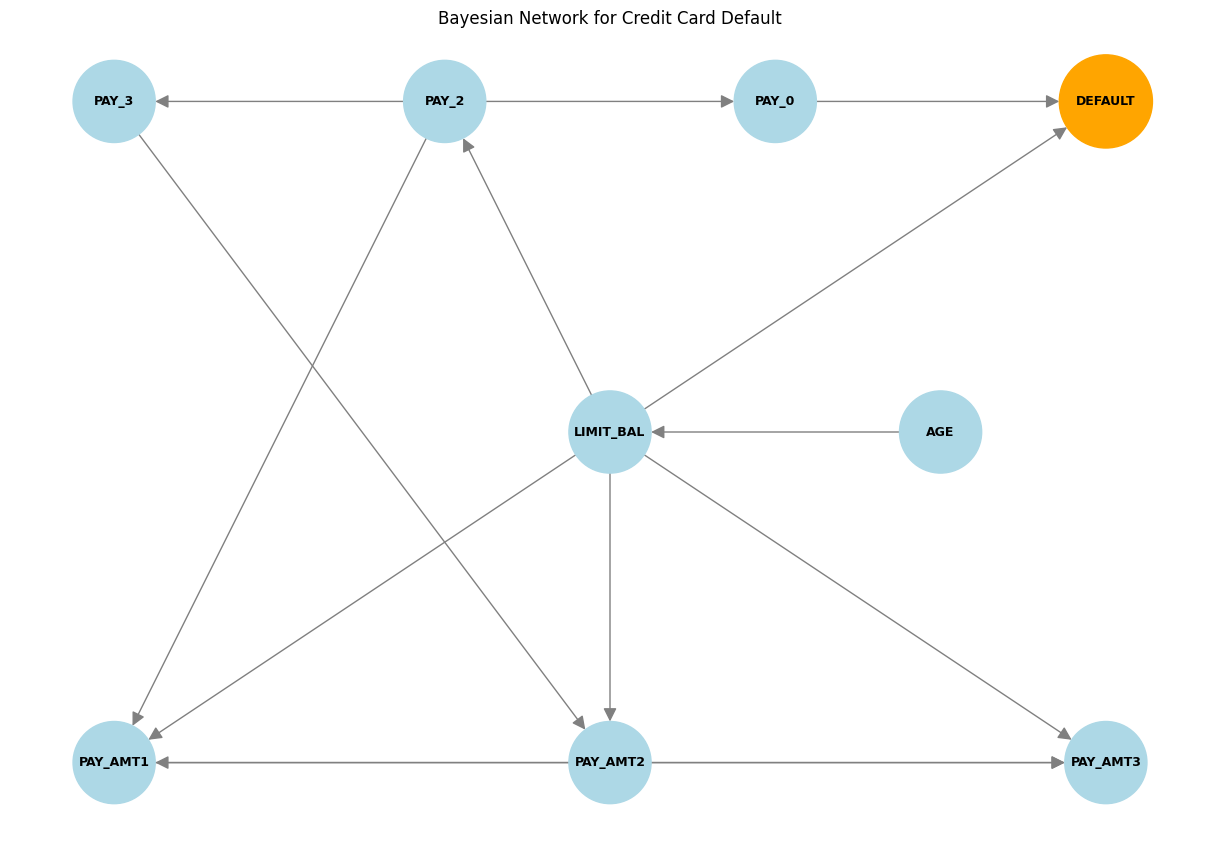

In [8]:
## 9. Visualize Bayesian Network

#Create a directed graph using the relationships
#identified by the Bayesian Network.
network_graph = nx.DiGraph()

network_graph.add_edges_from(
    bayesian_model.edges()
)

#Set the size of the graph.
plt.figure(figsize=(12, 8))

#Set the position of each variable to improve readability.
positions = {
    "PAY_3": (0, 2),
    "PAY_2": (2, 2),
    "PAY_0": (4, 2),
    "DEFAULT": (6, 2),
    "LIMIT_BAL": (3, 0),
    "AGE": (5, 0),
    "PAY_AMT1": (0, -2),
    "PAY_AMT2": (3, -2),
    "PAY_AMT3": (6, -2)
}

#Set a different color for the DEFAULT variable.
node_colors = [
    "orange" if node == "DEFAULT" else "lightblue"
    for node in network_graph.nodes()
]

#Set the size of each node
node_sizes = [
    4500 if node == "DEFAULT" else 3500
    for node in network_graph.nodes()
]

#Draw the Bayesian Network.
nx.draw(
    network_graph,
    positions,
    with_labels=True,
    node_size=node_sizes,
    node_color=node_colors,
    font_size=9,
    font_weight="bold",
    arrowsize=20,
    edge_color="gray"
)

plt.title("Bayesian Network for Credit Card Default")
plt.show()

Explanation:

The Bayesian Network shows several relationships between credit limit, repayment status, previous payment amounts, and DEFAULT. The two relationships most directly connected to DEFAULT were LIMIT_BAL → DEFAULT and PAY_0 → DEFAULT.

The network visualization also identifies relationships between the repayment status variables, which include PAY_2 → PAY_0 and PAY_2 → PAY_3. This indicates that the most recent repayment status and credit limit have direct relationships with DEFAULT within the learned network, while earlier repayment information is connected through other variables.

These relationships help showcase which variables are directly and indirectly connected to DEFAULT, providing useful information for understanding which customer characteristics may be associated with a higher risk of failing to make a payment.

Reference:

GeeksforGeeks. (2025). *Directed graphs, multigraphs and visualization in NetworkX*. https://www.geeksforgeeks.org/data-visualization/directed-graphs-multigraphs-and-visualization-in-networkx/

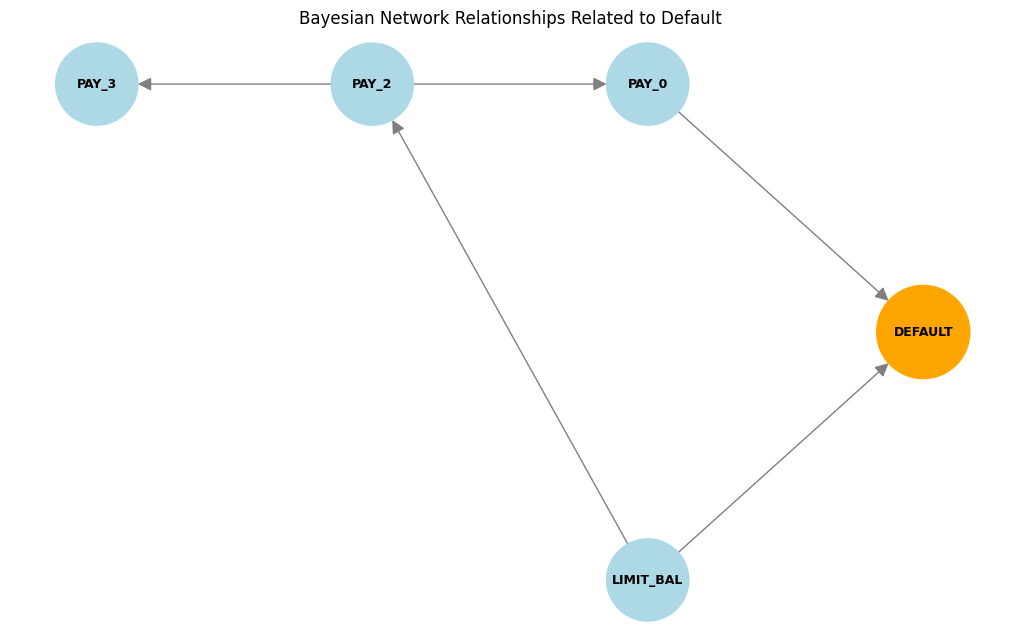

In [9]:
## 10. Default-Related Bayesian Network

#Select variables related to DEFAULT
default_variables = [
    "PAY_3",
    "PAY_2",
    "PAY_0",
    "LIMIT_BAL",
    "DEFAULT"
]

#Create smaller network with selected variables
default_network = network_graph.subgraph(
    default_variables
).copy()

#Set positions for each variable
default_positions = {
    "PAY_3": (0, 1),
    "PAY_2": (2, 1),
    "PAY_0": (4, 1),
    "LIMIT_BAL": (4, -1),
    "DEFAULT": (6, 0)
}

#Set DEFAULT to orange
default_colors = [
    "orange" if node == "DEFAULT" else "lightblue"
    for node in default_network.nodes()
]

#Make DEFAULT larger than other variables
default_sizes = [
    4500 if node == "DEFAULT" else 3500
    for node in default_network.nodes()
]

#Create graph
plt.figure(figsize=(10, 6))

#Draw Network
nx.draw(
    default_network,
    default_positions,
    with_labels=True,
    node_size=default_sizes,
    node_color=default_colors,
    font_size=9,
    font_weight="bold",
    arrowsize=20,
    edge_color="gray"
)

plt.title("Bayesian Network Relationships Related to Default")
plt.show()

Explanation:

What this network shows is a closer look at the variables connected to DEFAULT. Starting off with PAY_0 and LIMIT_BAL, both have a direct relationship with DEFAULT, while PAY_2 and PAY_3 are connected through other variables. For example, the network shows PAY_2 → PAY_0 → DEFAULT, while PAY_2 also has a relationship with PAY_3.

The network also shows LIMIT_BAL → PAY_2, while LIMIT_BAL itself is directly connected to DEFAULT. This smaller network was meant to provide an easier visualization of the pathways between the variables most closely connected to the target variable.

## 11. Conclusion

The Bayesian Network analysis was used in order to examine the connections between selected customer variables and credit card default. First, Hill Climb Search with the Bayesian Information Criterion (BIC) identified 14 relationships within the network. From these relationships, PAY_0 and LIMIT_BAL were directly connected to DEFAULT. As well, the network showed relationships between previous repayment statuses, which included PAY_2 being connected to both PAY_0 and PAY_3, while PAY_0 was directly connected to DEFAULT.

What these results indicate is that repayment status and credit limit were two of the variables most directly connected to DEFAULT within the learned network. The results also connect with the previous Bootstrap analysis, which showed a statistically significant difference in LIMIT_BAL between customers who defaulted and those who did not. The Bayesian Network provides another way of examining these selected variables by indicating how they are probabilistically connected to DEFAULT and one another.

The results from the Bayesian Network also connect with the Random Forest model used in the final project. The Random Forest identified PAY_0 as the most important predictor, with an importance value of approximately 0.1408, while LIMIT_BAL was ranked as the third most important predictor, with a value of approximately 0.0549. These two variables were also directly connected to DEFAULT within the Bayesian Network.

What these results suggest is that even though both models use different approaches, they identified some of the same variables as being useful when examining credit card default. While the Bayesian Network focused on the probabilistic relationships between the variables, the Random Forest measured their importance when predicting whether a customer would default. This provides additional support for the importance of repayment status and credit limit when examining customers who may have a higher risk of default.

One limitation of this analysis is that the Bayesian Network was used to examine the relationships between the variables rather than testing how accurately it could predict DEFAULT. Because of this, we cannot directly compare its predictive performance with the other models used in the final project. Another important limitation is that the relationships found within the network should not be interpreted as direct cause-and-effect relationships.

Overall, the Bayesian Network was able to showcase which selected variables had direct and indirect relationships with credit card default. When comparing these findings with the Bootstrap and Random Forest analyses, the results consistently highlighted repayment status and credit limit as useful variables for understanding credit card default. These findings help support the overall goal of the final project by providing a better understanding of which customer characteristics may be associated with a higher risk of failing to make a payment.